In [14]:
import numpy as np

In [15]:
class SGD:
    def __init__(self, lr=0.01):
        self.lr = lr

    def update(self, params, grads):
        for key in params:
            params[key] -= self.lr * grads[key]

In [16]:
class Momentum:
    def __init__(self, lr=0.01, momentum=0.9):
        self.lr = lr
        self.momentum = momentum
        self.v = None

    # 相比于SGD，这个在更新的时候考虑了v本身，所以可以避免方向上的轻缓问题
    def update(self, params, grads):
        if self.v is None:
            self.v = {}
            for key, val in params.items():
                self.v[key] = np.zeros_like(val)

        for key in params:
            self.v[key] = self.momentum * self.v[key] - self.lr * grads[key]
            params[key] += self.v[key]

In [17]:
class Adagrad:
    def __init__(self, lr=0.01):
        self.lr = lr
        self.h = None

    def update(self, params, grads):
        if self.h is None:
            self.h = {}
            for key, val in params.items():
                self.h[key] = np.zeros_like(val)

        for key in params:
            self.h[key] += grads[key] * grads[key]
            params[key] -= self.lr * grads[key] / (np.sqrt(self.h[key]) + 1e-7)

In [18]:
class Adam:
    def __init__(self, lr=0.001, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps

        self.step = 0
        self.m = None
        self.v = None

    def update(self, params, grads):
        # 只在第一次调用时初始化
        if self.m is None:
            self.m = {}
            self.v = {}

            for key, val in params.items():
                self.m[key] = np.zeros_like(val)
                self.v[key] = np.zeros_like(val)

        # 每次调用 update，次数加一
        self.step += 1

        for key in params:
            g = grads[key]

            # ① 梯度的历史平均
            self.m[key] = self.beta1 * self.m[key] + (1 - self.beta1) * g

            # ② 梯度平方的历史平均
            self.v[key] = self.beta2 * self.v[key] + (1 - self.beta2) * g**2

            # ③ 偏差校正
            m_hat = self.m[key] / (1 - self.beta1**self.step)
            v_hat = self.v[key] / (1 - self.beta2**self.step)

            # ④ 更新参数
            params[key] -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

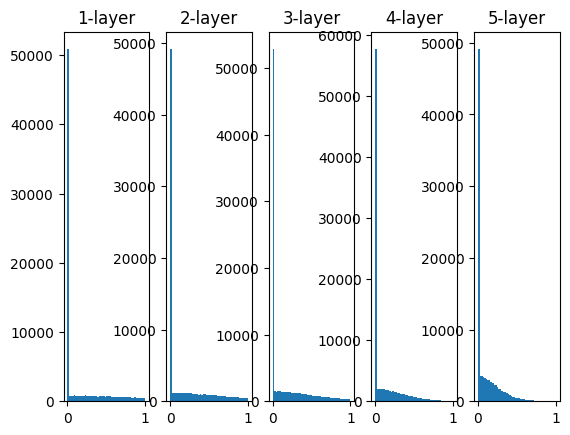

In [19]:
import matplotlib.pyplot as plt
from common.functions import *

x = np.random.randn(1000, 100)
node_num = 100  # 每个隐藏层有100个神经元
hidden_layer_size = 5  # 规定一共有5个隐藏层
activations = {}

for i in range(hidden_layer_size):
    if i != 0:
        x = activations[i - 1]

    # w = np.random.randn(node_num, node_num) * 1
    # w = np.random.randn(node_num,node_num) * 0.01
    w = np.random.randn(node_num, node_num) / np.sqrt(node_num)

    z = np.dot(x, w)
    a = relu(z)
    activations[i] = a

for i, a in activations.items():
    plt.subplot(1, len(activations), i + 1)
    plt.title(str(i + 1) + "-layer")
    plt.hist(a.flatten(), 50, range=(0, 1))

plt.show()

In [20]:
from common.mnist import *
from common.multi_layer_net import MultiLayerNet

(x_train, t_train), (x_test, t_test) = load_mnist(normalize=True, one_hot_label=True)

# 减少学习数据实现过拟合
x_train = x_train[:300]
t_train = t_train[:300]

network = MultiLayerNet(
    input_size=784, hidden_size_list=[100, 100, 100, 100, 100, 100], output_size=10
)

optimizer = SGD(lr=0.01)

max_epochs = 201
train_size = x_train.shape[0]
batch_size = 100

train_loss_list = []
train_acc_list = []
test_acc_list = []

iter_per_epoch = max(train_size / batch_size, 1)
epoch_cnt = 0

for i in range(1000000000):
    batch_mask = np.random.choice(train_size, batch_size)

    x_batch = x_train[batch_mask]
    t_batch = t_train[batch_mask]

    grads = network.gradient(x_batch, t_batch)
    optimizer.update(network.params, grads)

    if i % iter_per_epoch == 0:
        train_acc = network.accuracy(x_train, t_train)
        test_acc = network.accuracy(x_test, t_test)
        train_acc_list.append(train_acc)
        test_acc_list.append(test_acc)

        epoch_cnt += 1
        if epoch_cnt >= max_epochs:
            break

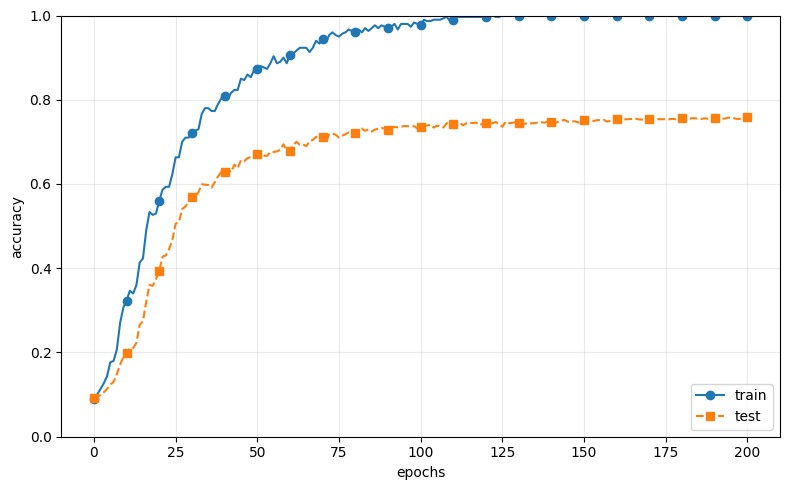

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# 每隔一个epoch记录一次准确率，按教材从0编号
epochs = np.arange(len(train_acc_list))

plt.figure(figsize=(8, 5))
plt.plot(
    epochs, train_acc_list, label="train", marker="o", markevery=10
)
plt.plot(
    epochs, test_acc_list, label="test", marker="s",
    markevery=10, linestyle="--"
)
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.ylim(0, 1.0)
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()